### Imports

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sympy as sp
from IPython.display import display, Math

### Parâmetros

In [13]:
Vref, CDAC, fclk, eps = 1.1, 0.5e-12, 250e6, 5e-4
t1 = 1/fclk/2                  # 2 ns
Vmin = Vref*(1-eps)            # 1.09945 V
gm_ID = 28                     # S/A (para calcular a corrente)
dV_max = 50e-3                 # queda máxima em Vout quando liga o CDAC (requisito do professor)

CD_min = CDAC*(Vref/dV_max - 1)  # CD mínimo para queda <= 50 mV  (= 10.5 pF)
CD_sel = 11e-12                # C_D escolhido
margem = 1.12                  # margem no gm (+12 %)

def Vout(t, gm, CD):
    gds = gm/10
    C = CD + CDAC
    return Vref - Vref*CDAC/C*np.exp(-(gm+gds)*t/C)

def erro(t, gm, CD):           # |Vref - Vout| calculado diretamente (evita arredondamentos)
    C = CD + CDAC
    return Vref*CDAC/C*np.exp(-1.1*gm*t/C)

def queda(CD):                 # queda inicial de Vout por partilha de carga com o CDAC
    return Vref*CDAC/(CD + CDAC)


### Procura de gm mínimo para C_D

In [14]:
gm_vals = np.arange(0.1e-3, 60e-3, 0.01e-3)  # gm de 0.1 mS a 60 mS, passo 10 uS

def gm_min_de(CD):
    ok = Vout(t1, gm_vals, CD) >= Vmin
    return gm_vals[ok][0]                      # o primeiro (menor) que cumpre

print(f"CD mínimo para queda <= {dV_max*1e3:.0f} mV: {CD_min*1e12:.2f} pF\n")
print(" CD [pF] | queda [mV] | queda<=50mV | gm min [mS] | ID [uA]")
CD_vals = np.r_[np.arange(1e-12, 15.01e-12, 1e-12), CD_min]
for CD in np.sort(CD_vals):
    gm_min = gm_min_de(CD)
    print(f" {CD*1e12:6.2f}  |  {queda(CD)*1e3:7.1f}   |     {'sim' if queda(CD) <= dV_max+1e-12 else 'não':3s}     |"
          f"   {gm_min*1e3:6.2f}    | {gm_min/gm_ID*1e6:6.0f}")

# ponto escolhido
gm_sel = 25e-3     # em vez de  gm_sel = margem*gm_min_de(CD_sel)
# margem*gm_min_de(CD_sel)
print(f"\nEscolha: CD = {CD_sel*1e12:.2f} pF, gm = {gm_sel*1e3:.2f} mS "
      f"(mínimo {gm_min_de(CD_sel)*1e3:.2f} mS + {100*(margem-1):.0f} %)")
print(f"  queda inicial = {queda(CD_sel)*1e3:.1f} mV  (máx {dV_max*1e3:.0f} mV)")
print(f"  Vout(2ns) = {Vout(t1, gm_sel, CD_sel):.6f} V  (limite {Vmin:.6f} V)")
print(f"  erro = {erro(t1, gm_sel, CD_sel)*1e3:.3f} mV  (máx {Vref*eps*1e3:.2f} mV)")
print(f"  I_D11 = {gm_sel/gm_ID*1e6:.0f} uA  (gm/ID = {gm_ID} S/A)")

CD mínimo para queda <= 50 mV: 10.50 pF

 CD [pF] | queda [mV] | queda<=50mV | gm min [mS] | ID [uA]
   1.00  |    366.7   |     não     |     4.44    |    159
   2.00  |    220.0   |     não     |     6.81    |    243
   3.00  |    157.1   |     não     |     9.00    |    321
   4.00  |    122.2   |     não     |    11.06    |    395
   5.00  |    100.0   |     não     |    13.01    |    465
   6.00  |     84.6   |     não     |    14.88    |    531
   7.00  |     73.3   |     não     |    16.69    |    596
   8.00  |     64.7   |     não     |    18.43    |    658
   9.00  |     57.9   |     não     |    20.11    |    718
  10.00  |     52.4   |     não     |    21.75    |    777
  10.50  |     50.0   |     sim     |    22.55    |    805
  11.00  |     47.8   |     sim     |    23.35    |    834
  12.00  |     44.0   |     sim     |    24.90    |    889
  13.00  |     40.7   |     sim     |    26.42    |    944
  14.00  |     37.9   |     sim     |    27.91    |    997
  15.00  |    

### Gráficos

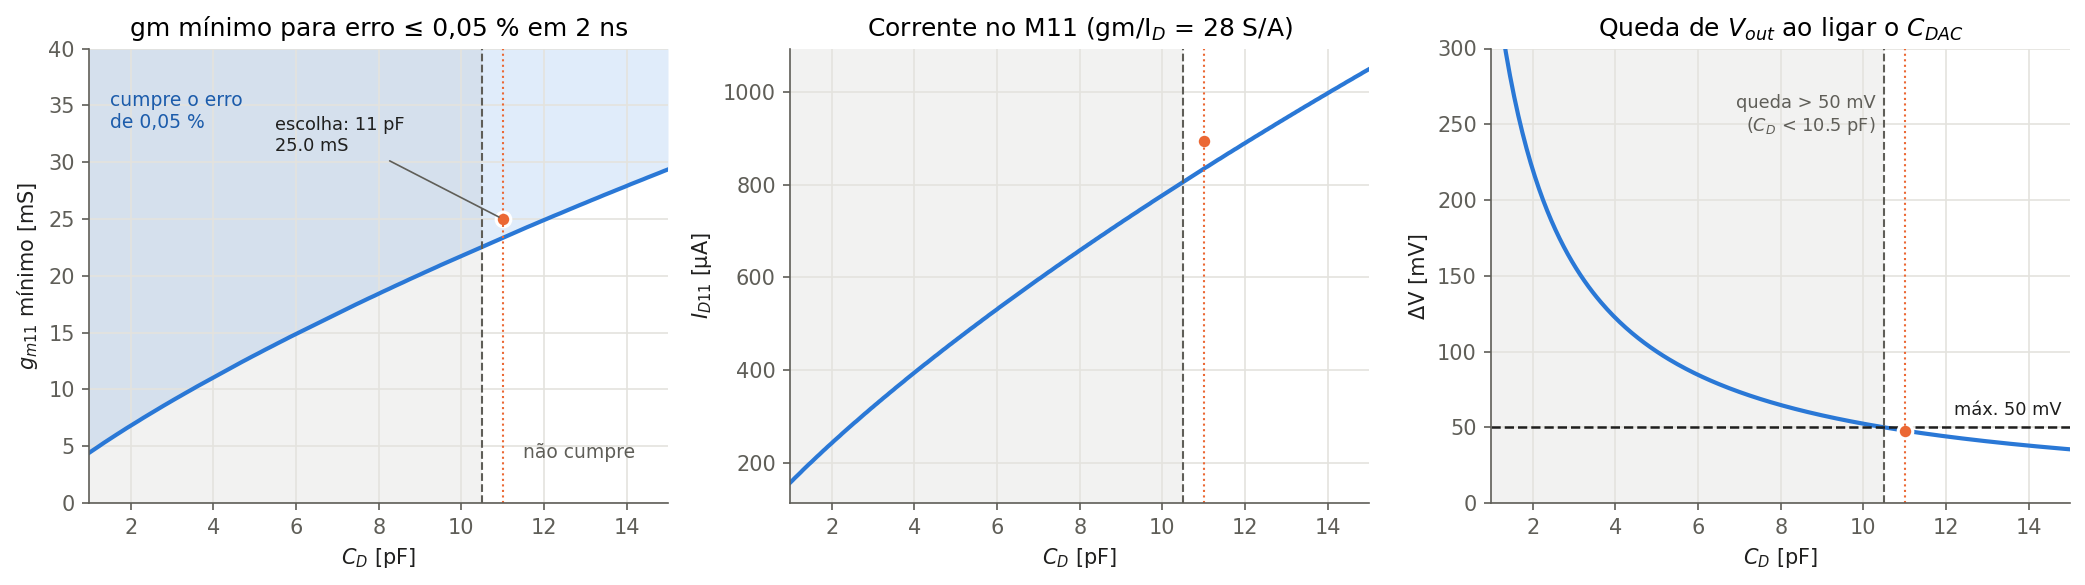

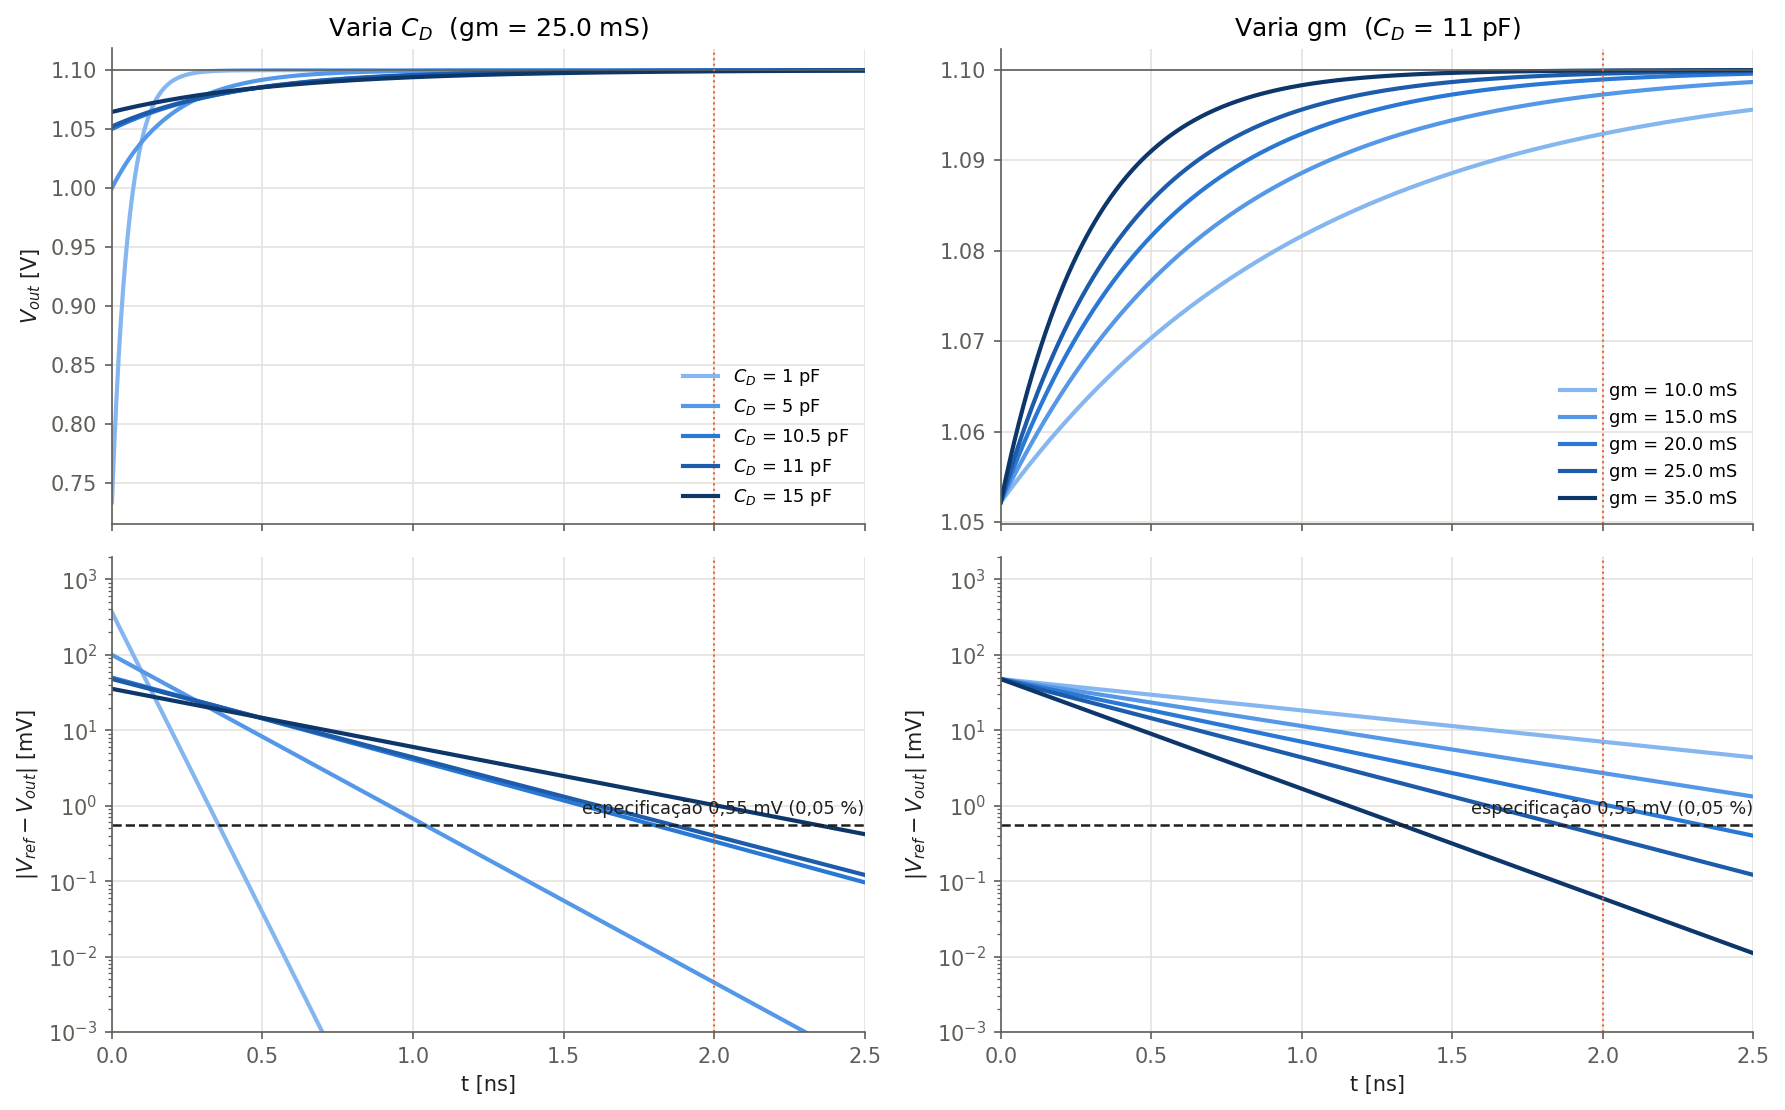

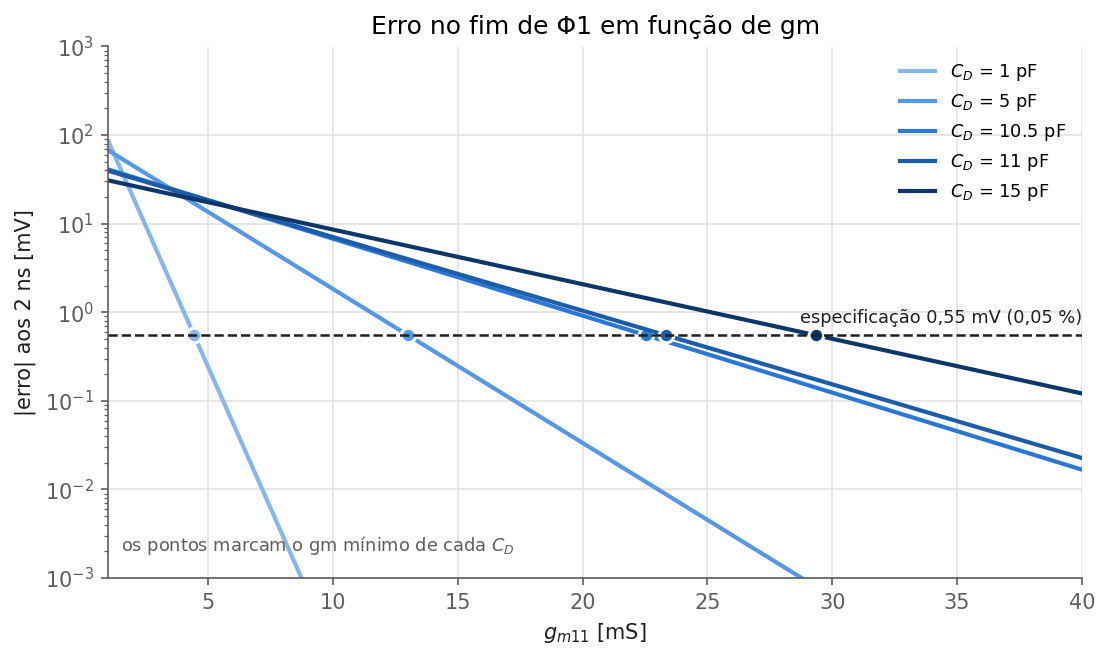

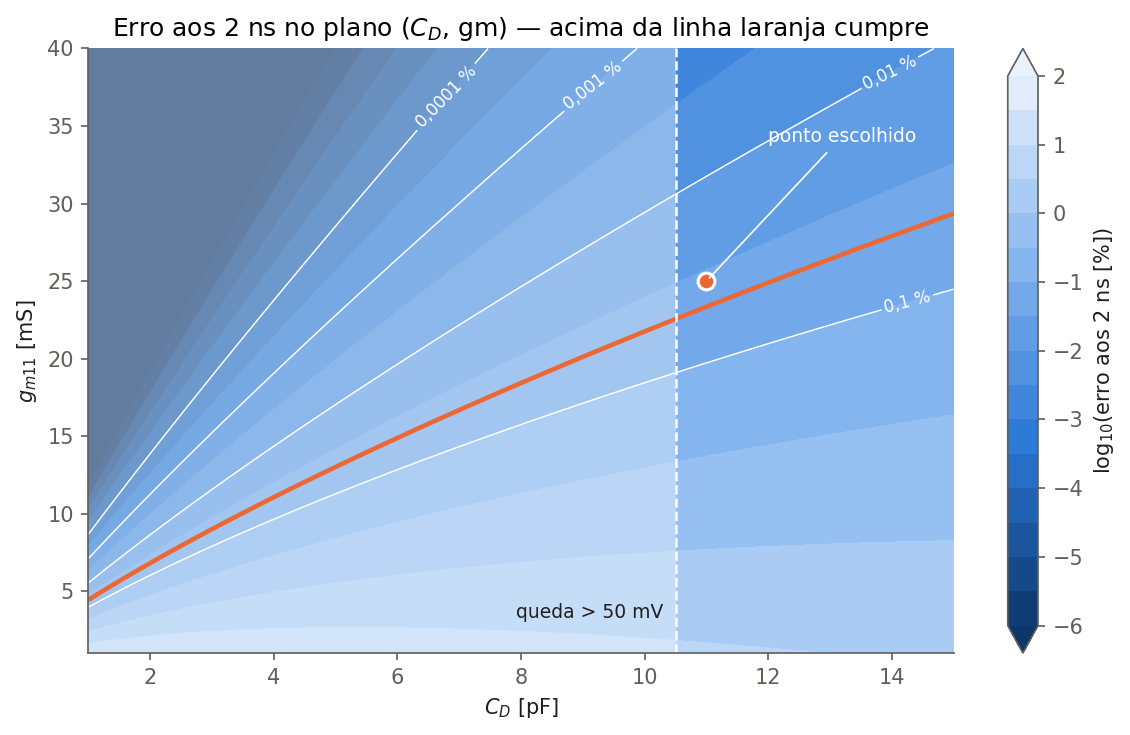

In [15]:
INK, INK2, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # claro -> escuro
ACC = "#eb6834"                                                  # ponto escolhido
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 150})
Emax = Vref*eps*1e3            # 0.55 mV
def linha_spec(ax):
    ax.axhline(Emax, color=INK, ls="--", lw=1.2)
    ax.text(ax.get_xlim()[1], Emax*1.25, "especificação 0,55 mV (0,05 %)",
            ha="right", va="bottom", color=INK, fontsize=8.5)
def zona_CDmin(ax):            # sombreia CD < CD_min (queda > 50 mV)
    ax.axvspan(ax.get_xlim()[0], CD_min*1e12, color=INK2, alpha=0.08, lw=0)
    ax.axvline(CD_min*1e12, color=INK2, lw=1, ls="--")

CDp = np.linspace(1e-12, 15e-12, 281)          # eixo dos gráficos: 1 a 15 pF
XL = (1, 15)

# ---- Fig. 1: gm mínimo, corrente e queda em função de C_D ----
gmm = np.array([gm_min_de(c) for c in CDp])
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a in ax: a.set_xlim(*XL)
ax[0].plot(CDp*1e12, gmm*1e3, color=RAMP[2])
ax[0].fill_between(CDp*1e12, gmm*1e3, 40, color=RAMP[0], alpha=0.25, lw=0)
ax[0].text(1.5, 33, "cumpre o erro\nde 0,05 %", color=RAMP[3], fontsize=9)
ax[0].text(11.5, 4, "não cumpre", color=INK2, fontsize=9)
ax[0].plot(CD_sel*1e12, gm_sel*1e3, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[0].annotate(f"escolha: {CD_sel*1e12:g} pF\n{gm_sel*1e3:.1f} mS", (CD_sel*1e12, gm_sel*1e3),
               (5.5, 31), color=INK, fontsize=8.5, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax[0].set(xlabel="$C_D$ [pF]", ylabel="$g_{m11}$ mínimo [mS]", ylim=(0, 40),
          title="gm mínimo para erro ≤ 0,05 % em 2 ns")
ax[1].plot(CDp*1e12, gmm/gm_ID*1e6, color=RAMP[2])
ax[1].plot(CD_sel*1e12, gm_sel/gm_ID*1e6, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[1].set(xlabel="$C_D$ [pF]", ylabel="$I_{D11}$ [µA]",
          title=f"Corrente no M11 (gm/I$_D$ = {gm_ID} S/A)")
ax[2].plot(CDp*1e12, queda(CDp)*1e3, color=RAMP[2])
ax[2].axhline(dV_max*1e3, color=INK, ls="--", lw=1.2)
ax[2].text(14.8, dV_max*1e3+8, "máx. 50 mV", ha="right", color=INK, fontsize=8.5)
ax[2].plot(CD_sel*1e12, queda(CD_sel)*1e3, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[2].set(xlabel="$C_D$ [pF]", ylabel="ΔV [mV]", ylim=(0, 300),
          title="Queda de $V_{out}$ ao ligar o $C_{DAC}$")
for a in ax:
    zona_CDmin(a)
    a.axvline(CD_sel*1e12, color=ACC, lw=1, ls=":")
ax[2].text(CD_min*1e12-0.2, 270, f"queda > 50 mV\n($C_D$ < {CD_min*1e12:.1f} pF)",
           ha="right", va="top", color=INK2, fontsize=8.5)
plt.tight_layout(); plt.savefig("fig1_gm_vs_CD.png")

# ---- Fig. 2: Vout(t) e erro(t) — varia C_D | varia gm ----
t = np.linspace(0, 2.5e-9, 1000)
CD_list = [1e-12, 5e-12, CD_min, CD_sel, 15e-12]
gm_list = [10e-3, 15e-3, 20e-3, gm_sel, 35e-3]
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for i, c in enumerate(CD_list):
    ax[0,0].plot(t*1e9, Vout(t, gm_sel, c), color=RAMP[i], label=f"$C_D$ = {c*1e12:g} pF")
    ax[1,0].semilogy(t*1e9, erro(t, gm_sel, c)*1e3, color=RAMP[i])
for i, g in enumerate(gm_list):
    ax[0,1].plot(t*1e9, Vout(t, g, CD_sel), color=RAMP[i], label=f"gm = {g*1e3:.1f} mS")
    ax[1,1].semilogy(t*1e9, erro(t, g, CD_sel)*1e3, color=RAMP[i])
ax[0,0].set(title=f"Varia $C_D$  (gm = {gm_sel*1e3:.1f} mS)", ylabel="$V_{out}$ [V]")
ax[0,1].set(title=f"Varia gm  ($C_D$ = {CD_sel*1e12:g} pF)")
for a in ax[0]:
    a.axhline(Vref, color=INK2, lw=0.8); a.legend(loc="lower right", fontsize=8.5)
for a in ax[1]:
    a.set(xlabel="t [ns]", ylabel="|$V_{ref}-V_{out}$| [mV]", ylim=(1e-3, 2e3), xlim=(0, 2.5))
    linha_spec(a)
for a in ax.flat:
    a.axvline(t1*1e9, color=ACC, lw=1, ls=":")
plt.tight_layout(); plt.savefig("fig2_Vout_t.png")

# ---- Fig. 3: erro aos 2 ns em função de gm, várias C_D ----
gm = np.linspace(1e-3, 40e-3, 500)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, c in enumerate(CD_list):
    ax.semilogy(gm*1e3, erro(t1, gm, c)*1e3, color=RAMP[i], label=f"$C_D$ = {c*1e12:g} pF")
    ax.plot(gm_min_de(c)*1e3, Emax, "o", color=RAMP[i], ms=7, mec="white", mew=1.5)
ax.set(xlabel="$g_{m11}$ [mS]", ylabel="|erro| aos 2 ns [mV]", xlim=(1, 40), ylim=(1e-3, 1e3),
       title="Erro no fim de Φ1 em função de gm")
linha_spec(ax); ax.legend(loc="upper right", fontsize=8.5)
ax.text(1.5, 2e-3, "os pontos marcam o gm mínimo de cada $C_D$", color=INK2, fontsize=8.5)
plt.tight_layout(); plt.savefig("fig3_erro_vs_gm.png")

# ---- Fig. 4: mapa do erro no plano (C_D, gm) ----
X, Y = np.meshgrid(np.linspace(1e-12, 15e-12, 301), np.linspace(1e-3, 40e-3, 301))
Z = np.log10(erro(t1, Y, X)/Vref*100)      # log10(erro em %)
cmap = LinearSegmentedColormap.from_list("blues", ["#0d366b", "#2a78d6", "#86b6ef", "#e8f1fc"])
fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contourf(X*1e12, Y*1e3, Z, levels=np.arange(-6, 2.01, 0.5), cmap=cmap, extend="both")
cl = ax.contour(X*1e12, Y*1e3, Z, levels=[-4, -3, -2, -1], colors="white",
                linewidths=0.7, linestyles="solid")
ax.clabel(cl, fmt={-4: "0,0001 %", -3: "0,001 %", -2: "0,01 %", -1: "0,1 %"}, fontsize=8)
ax.contour(X*1e12, Y*1e3, Z, levels=[np.log10(eps*100)], colors=ACC,
           linewidths=2.2, linestyles="solid")
ax.axvspan(1, CD_min*1e12, color="white", alpha=0.35, lw=0)
ax.axvline(CD_min*1e12, color="white", lw=1.2, ls="--")
ax.text(CD_min*1e12-0.2, 3, "queda > 50 mV", ha="right", va="bottom", color=INK, fontsize=9)
ax.plot(CD_sel*1e12, gm_sel*1e3, "o", color=ACC, ms=8, mec="white", mew=1.5)
ax.annotate("ponto escolhido", (CD_sel*1e12, gm_sel*1e3), (12, 34), color="white", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="white", lw=0.8))
fig.colorbar(cs).set_label("log$_{10}$(erro aos 2 ns [%])")
ax.grid(False)
ax.set(xlabel="$C_D$ [pF]", ylabel="$g_{m11}$ [mS]",
       title="Erro aos 2 ns no plano ($C_D$, gm) — acima da linha laranja cumpre")
plt.tight_layout(); plt.savefig("fig4_mapa_CD_gm.png")

plt.show()

### Alínea B) e C) - Função transferência

   C1 (vx)    = C_db1B + C_gd2B + C_gs5
   C2 (Vctr)  = C_p + C_db5 + C_db4 + C_gd4 + C_gs11 + C_gd11 + C_gd1
   C3 (nó M2B/M3B) = C_gs2B + C_gd3B + C_db3B
   C4 (VoutR) = C_db1 + C_dbIB3 + C_gs1A + C_gd1A
   Flutuantes: C_gd1B, C_db2B, C_gd5, C_c, C_gs1

In [20]:
# ---- símbolos ----
s = sp.symbols('s')
V1, V2, V3, Vo, Vr = sp.symbols('V1 V2 V3 V_outR V_ref')   # Vr (não Vref: Vref = 1.1 V lá em cima)

gm1B, gm2B, gm5, gm1 = sp.symbols('g_m1B g_m2B g_m5 g_m1', positive=True)
gds1B, gds2B, gds3B, gds4, gds5, gds1, gdsIB3 = sp.symbols(
    'g_ds1B g_ds2B g_ds3B g_ds4 g_ds5 g_ds1 g_dsIB3', positive=True)
C1, C2, C3, C4 = sp.symbols('C_1 C_2 C_3 C_4', positive=True)      # capacidades à massa de cada nó
Cgd1B, Cdb2B, Cgd5, Cc, Cgs1 = sp.symbols('C_gd1B C_db2B C_gd5 C_c C_gs1', positive=True)  # flutuantes

# ---- equações nodais (soma das correntes que saem = 0) ----
eqs = [
    gm1B*Vr + V1*gds1B + (V1-V3)*gds2B + gm2B*(-V3)
      + s*(V1*C1 + (V1-Vr)*Cgd1B + (V1-V3)*Cdb2B + (V1-V2)*Cgd5),                    # V1
    gm5*V1 + V2*(gds4+gds5) + s*(V2*C2 + (V2-V1)*Cgd5 + (V2-V3)*Cc + (V2-Vo)*Cgs1),   # V2
    V3*gds3B + (V3-V1)*gds2B - gm2B*(-V3) + s*(V3*C3 + (V3-V1)*Cdb2B + (V3-V2)*Cc),   # V3
    -gm1*(V2-Vo) + Vo*(gds1+gdsIB3) + s*(Vo*C4 + (Vo-V2)*Cgs1),                       # VoutR
]

# ---- resolver (regra de Cramer) ----
Y, rhs = sp.linear_eq_to_matrix(eqs, [V1, V2, V3, Vo])
D = sp.expand(Y.det(method='berkowitz'))
Y4 = Y.copy(); Y4[:, 3] = rhs
N = sp.expand(Y4.det(method='berkowitz') / Vr)
if sp.Poly(D, s).coeff_monomial(1).could_extract_minus_sign():   # termo s^0 positivo
    N, D = -N, -D
H = N / D                                                        # função de transferência

# ---- H(s) completa em fração ----
N_s = sp.collect(N, s)
D_s = sp.collect(D, s)
display(Math(r"H(s) = \frac{V_{outR}}{V_{ref}} = \frac{" + sp.latex(N_s) + "}{" + sp.latex(D_s) + "}"))


# ---- ganho DC ----
N0 = sp.expand(N.subs(s, 0))          # numerador em s = 0
D0 = sp.expand(D.subs(s, 0))          # denominador em s = 0
A0 = N0 / D0

display(Math(r"A_0 = H(0) = \frac{" + sp.latex(sp.factor(N0)) + "}{" + sp.latex(sp.factor(D0)) + "}"))

# ---- polos e zeros ----
valores = {
    gm1B: None, gm2B: None, gm5: None, gm1: None,
    gds1B: None, gds2B: None, gds3B: None, gds4: None, gds5: None, gds1: None, gdsIB3: None,
    C1: None, C2: None, C3: None, C4: None,
    Cgd1B: None, Cdb2B: None, Cgd5: None, Cc: None, Cgs1: None,
}

# 2) valores numéricos (só quando o dicionário estiver preenchido)
if None in valores.values():
    print("\nPolos/zeros: preencher o dicionário 'valores' para os calcular.")
else:
    Dn = sp.Poly(D.subs(valores), s)
    Nn = sp.Poly(N.subs(valores), s)
    a = [float(c) for c in Dn.all_coeffs()]          # s^4 ... s^0
    b = [float(c) for c in Nn.all_coeffs()]
    A0n = float(A0.subs(valores))

    # equações com números
    display(Math(r"A_0 = " + sp.latex(sp.Float(A0n, 4)) +
                 rf"\;\; ({20*np.log10(abs(A0n)):.1f}\ \mathrm{{dB}})"))
    display(Math(r"D(s) = " + sp.latex(sp.Poly([sp.Float(x, 4) for x in a], s).as_expr()) + r" = 0"))
    display(Math(r"N(s) = " + sp.latex(sp.Poly([sp.Float(x, 4) for x in b], s).as_expr()) + r" = 0"))

    # raízes
    polos, zeros = np.roots(a), np.roots(b)
    fmt = lambda r: (rf"{r.real/(2*np.pi):.4g}" if abs(r.imag) < 1e-9*abs(r)
                     else rf"{r.real/(2*np.pi):.4g} \pm j\,{abs(r.imag)/(2*np.pi):.4g}")
    unicos = lambda v: [r for r in v if r.imag >= 0]   # mostra cada par complexo só uma vez
    display(Math(r"\text{Polos [Hz]: } " + r",\quad ".join(fmt(p) for p in unicos(polos))))
    display(Math(r"\text{Zeros [Hz]: } " + r",\quad ".join(fmt(z) for z in unicos(zeros))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Polos/zeros: preencher o dicionário 'valores' para os calcular.


In [21]:
# ================= Alínea d): modelo simplificado (3 nós) =================
g1, g2 = sp.symbols('g_1 g_2', positive=True)   # g1 = gds1B + gds2B*gds3B/gm2B ; g2 = gds4 + gds5

eqs_s = [
    gm1B*Vr + g1*V1 - gm2B*V3 + s*C1*V1,                 # V1 (vx)
    gm5*V1 + g2*V2 + s*(C2*V2 + Cc*(V2 - V3)),           # V2 (Vctr)
    gm2B*V3 + s*(C3*V3 + Cc*(V3 - V2)),                  # V3 (fonte do M2B)
]
Ys, rhs_s = sp.linear_eq_to_matrix(eqs_s, [V1, V2, V3])
Ds = sp.expand(Ys.det())
Ys2 = Ys.copy(); Ys2[:, 1] = rhs_s                       # saída = V2 (≈ VoutR)
Ns = sp.expand(Ys2.det() / Vr)
if sp.Poly(Ds, s).coeff_monomial(1).could_extract_minus_sign():
    Ns, Ds = -Ns, -Ds

a = [sp.factor(sp.Poly(Ds, s).coeff_monomial(s**k)) for k in range(4)]
b = [sp.factor(sp.Poly(Ns, s).coeff_monomial(s**k)) for k in range(2)]

display(Math(r"H(s) \approx \frac{" + sp.latex(sp.collect(Ns, s)) + "}{" + sp.latex(sp.collect(Ds, s)) + "}"))

# ---- expressões aproximadas ----
A0_s  = sp.simplify(b[0]/a[0])
p1    = -a[0]/a[1].subs({g1: 0, g2: 0})          # polo dominante (gm >> g)
GBW   = sp.simplify(A0_s * -p1)
z1    = -b[0]/b[1]                               # zero (semiplano esquerdo)
w0    = sp.sqrt(a[1].subs({g1: 0, g2: 0}) / a[3].subs({C3: 0}))   # par não dominante (C3 << C1, C2, Cc)

display(Math(r"A_0 = " + sp.latex(A0_s)))
display(Math(r"p_1 \approx " + sp.latex(sp.simplify(p1))))
display(Math(r"GBW \approx " + sp.latex(GBW)))
display(Math(r"z_1 = " + sp.latex(sp.simplify(z1))))
display(Math(r"\omega_0 \approx " + sp.latex(sp.simplify(w0))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>